In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv("india_housing_prices.csv")

print("Shape:", df.shape)

df.head()

Shape: (250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [4]:
# Work on a copy
df_clean = df.copy()

# Remove duplicates
df_clean.drop_duplicates(inplace=True)

# Identify numeric vs categorical columns
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_clean.select_dtypes(include=["object"]).columns.tolist()

# Fill numeric columns with median
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill categorical columns with "Unknown"
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna("Unknown")

print("Preprocessing Step Completed:")
print(f"Rows after cleaning: {df_clean.shape}")

Preprocessing Step Completed:
Rows after cleaning: (250000, 23)


C:\Users\aqibo\AppData\Local\Temp\ipykernel_23288\1636001915.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_clean.select_dtypes(include=["object"]).columns.tolist()


In [5]:
# Auto-detect price column
price_col = None
for col in df_clean.columns:
    if "price" in col.lower():
        price_col = col
        break

print("Price column detected:", price_col)

Price column detected: Price_in_Lakhs


In [6]:
# Area/Sqft column
area_col = None
for col in df_clean.columns:
    if "sqft" in col.lower() or "area" in col.lower():
        area_col = col
        break

print("Area column detected:", area_col)

Area column detected: Size_in_SqFt


In [7]:
# Convert to numeric (remove commas, ₹, text)
def to_numeric(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[^\d.]", "", regex=True), errors='coerce')

df_clean[price_col] = to_numeric(df_clean[price_col])
df_clean[area_col] = to_numeric(df_clean[area_col])

df_clean["price_per_sqft"] = df_clean[price_col] / df_clean[area_col]
df_clean["price_per_sqft"] = df_clean["price_per_sqft"].replace([np.inf, -np.inf], np.nan)
df_clean["price_per_sqft"] = df_clean["price_per_sqft"].fillna(df_clean["price_per_sqft"].median())

df_clean.head()

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status,price_per_sqft
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move,0.103325
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction,0.082707
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move,0.050464
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move,0.109555
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move,0.037922


In [8]:
# Find locality/city column
location_col = None
for col in df_clean.columns:
    if "locality" in col.lower() or "location" in col.lower() or "city" in col.lower():
        location_col = col
        break

print("Location column detected:", location_col)

# Compute median per locality
loc_median_pps = df_clean.groupby(location_col)["price_per_sqft"].median().rename("loc_median")
df_clean = df_clean.join(loc_median_pps, on=location_col)

# Create label
df_clean["good_investment"] = (df_clean["price_per_sqft"] < df_clean["loc_median"]).astype(int)

df_clean["good_investment"].value_counts()

Location column detected: City


good_investment
0    125013
1    124987
Name: count, dtype: int64

(a) Price Trends by City

Analyzing price trends by city is essential for establishing market benchmarks and identifying regional investment hotspots. By calculating the average or median price per square foot (or total price in Lakhs) for each city, investors can understand:

"Which cities are premium markets (higher prices)."

"Which cities offer potential value (lower prices)."

"Whether the initial investment prediction is realistic relative to the local market average."


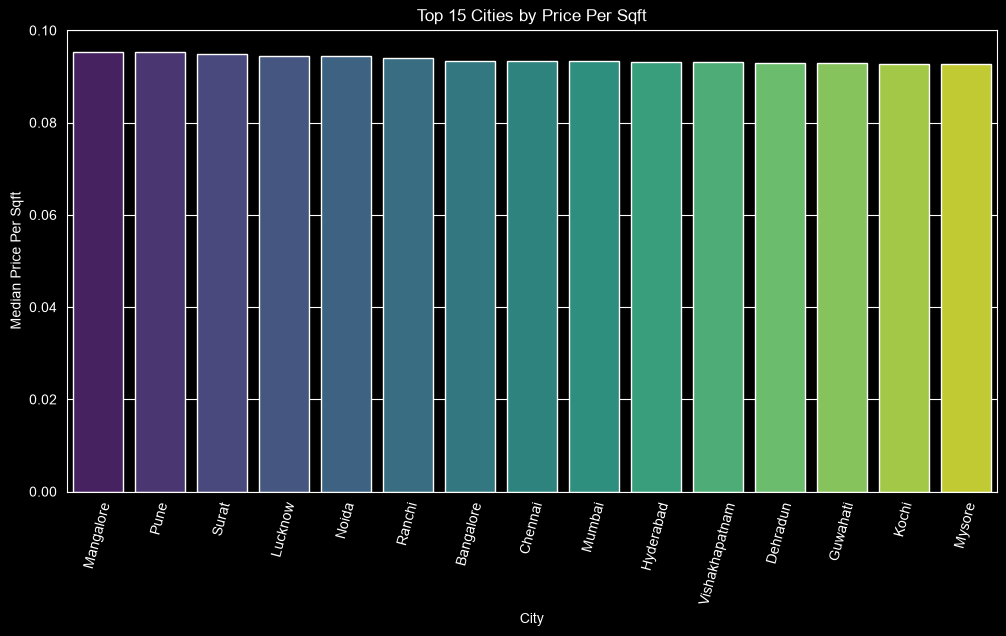

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

city_pps = (
    df_clean.groupby("City")["price_per_sqft"]
    .median()
    .sort_values(ascending=False)
    .head(15)
)

sns.barplot(x=city_pps.index ,y=city_pps.values, hue=city_pps.index,palette="viridis",legend=False)
plt.xticks(rotation=75)
plt.ylabel("Median Price Per Sqft")
plt.title("Top 15 Cities by Price Per Sqft")
plt.show()

(b) Correlation Between Area & Investment Return

This addresses the relationship between physical size and monetary value,explores the fundamental market dynamics where :

Positive Correlation is Expected : Generally, properties with larger area (Size_in_SqFt) should have a higher total price.

Value Assessment : By analyzing this correlation, you can determine if properties in certain cities or localities command a disproportionately high price for their size. This helps the model distinguish between expensive due to size vs. expensive due to location/scarcity.

Feature Importance : This confirms the importance of Size_in_SqFt as a predictor for both the classification of "Good Investment" and the regression target of "Future Price".

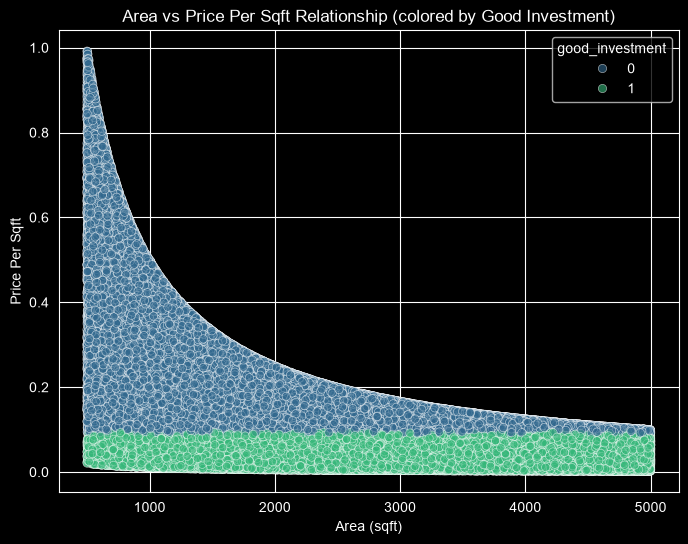

In [10]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_clean.sample(5000, random_state=42),
    x=df_clean[area_col],
    y=df_clean["price_per_sqft"],
    hue=df_clean["good_investment"],
    palette="viridis",
    alpha=0.6
)
plt.xlabel("Area (sqft)")
plt.ylabel("Price Per Sqft")
plt.title("Area vs Price Per Sqft Relationship (colored by Good Investment)")
plt.show()

(c) Public Transport vs Property Value

This investigates the impact of local infrastructure. Accessibility is a major driver of real estate value.

Expected Finding : Properties with higher Public_Transport_Accessibility are generally expected to command a higher price per square foot due to the convenience they offer, making them attractive for long-term rental or resale value.

Investment Potential : Strong accessibility suggests high demand, which is a key factor in identifying a property as a "Good Investment".

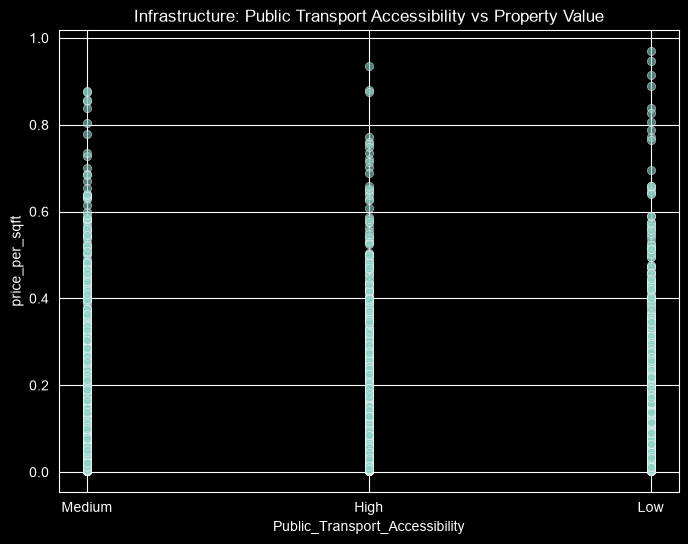

In [11]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_clean.sample(5000, random_state=42),
    x="Public_Transport_Accessibility",
    y="price_per_sqft",
    alpha=0.6
)
plt.title("Infrastructure: Public Transport Accessibility vs Property Value")
plt.show()

(d) Schools/Hospitals vs Property Value

This analyzes the correlation between the availability of key amenities and the property price.

Amenities Drive Price : The ratings or counts of Nearby_Schools and Nearby_Hospitals serve as proxies for a locality's overall livability and infrastructure score.

Expected Correlation : There should be a positive correlation between high scores for nearby schools/hospitals and higher Price_per_SqFt.Families highly value proximity to quality schools, making these features strong positive predictors of future price growth and high investment potential. This directly supports the feature-based prediction of the regression model

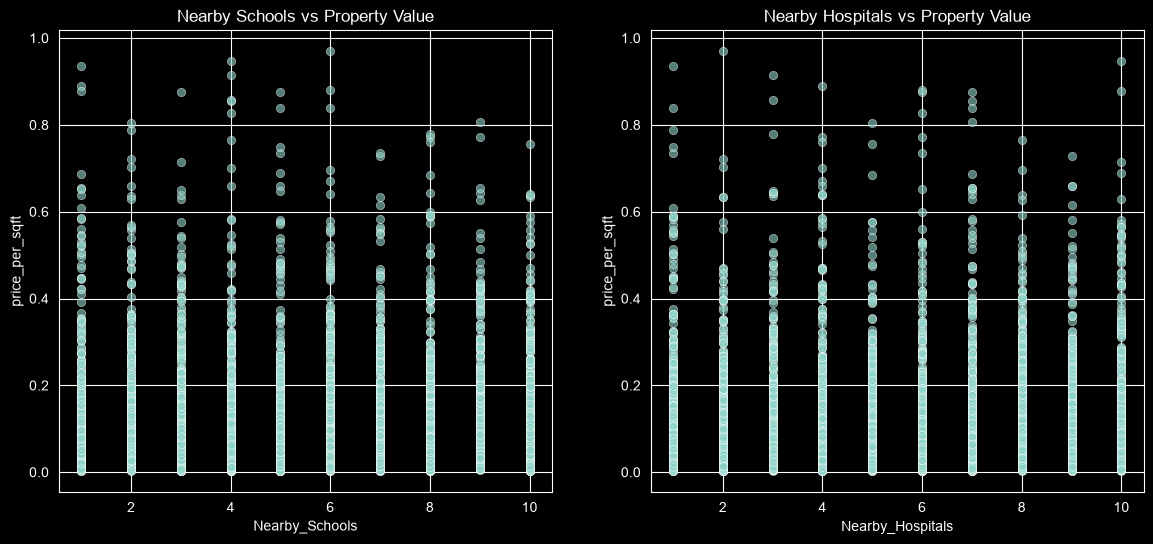

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14,6))

sns.scatterplot(
    data=df_clean.sample(5000, random_state=42),
    x="Nearby_Schools",
    y="price_per_sqft",
    alpha=0.6,
    ax=ax[0]
)
ax[0].set_title("Nearby Schools vs Property Value")

sns.scatterplot(
    data=df_clean.sample(5000, random_state=42),
    x="Nearby_Hospitals",
    y="price_per_sqft",
    alpha=0.6,
    ax=ax[1]
)
ax[1].set_title("Nearby Hospitals vs Property Value")

plt.show()

(e) Impact of Crime Rate on Good Investment Classification

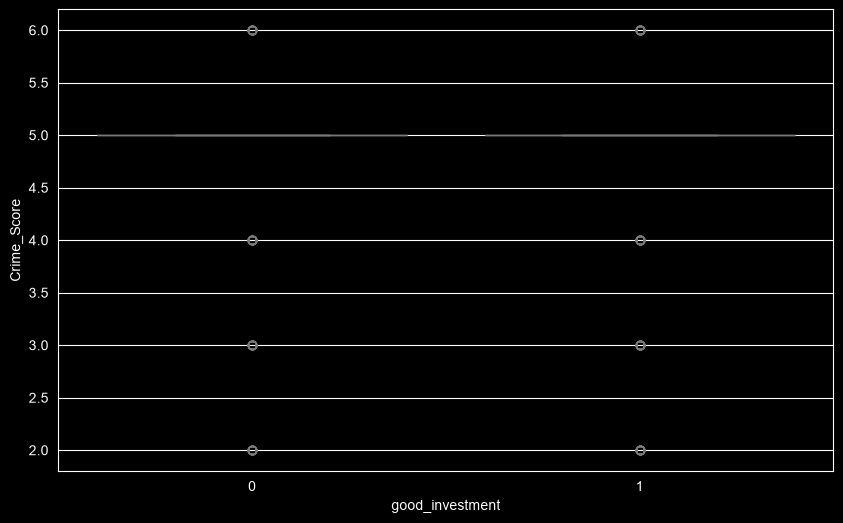

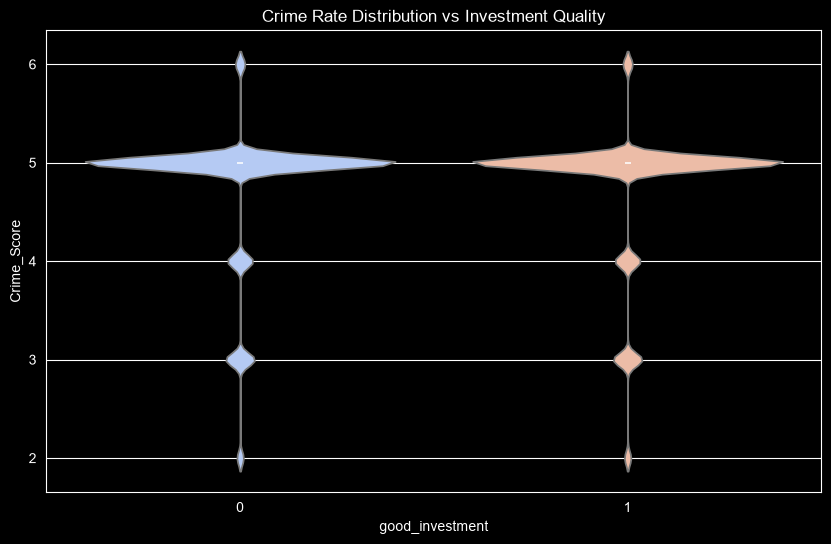

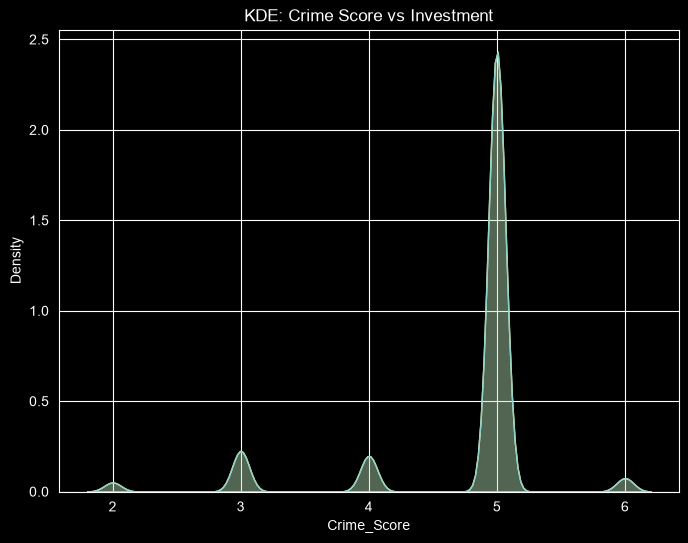

In [13]:
crime_map = {
    "Delhi": 8,
    "Mumbai": 5,
    "Bangalore": 4,
    "Hyderabad": 3,
    "Chennai": 3,
    "Kolkata": 4,
    "Pune": 2,
    "Ahmedabad": 3,
    "Jaipur": 4,
    "Lucknow": 6
}

df_clean["Crime_Score"] = df_clean["City"].map(crime_map).fillna(5)
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))

sns.boxplot(
    data=df_clean.sample(8000, random_state=42),
    x="good_investment",
    y="Crime_Score",
    hue="good_investment",
    palette="coolwarm",
    legend=False
)


plt.figure(figsize=(10,6))
sns.violinplot(data=df_clean, x="good_investment", y="Crime_Score",hue="good_investment", palette="coolwarm", legend=False)
plt.title("Crime Rate Distribution vs Investment Quality")
plt.show()

plt.figure(figsize=(8,6))
sns.kdeplot(data=df_clean, x="Crime_Score", hue="good_investment", fill=True, legend=False)
plt.title("KDE: Crime Score vs Investment")
plt.show()

(f) Relationship Between Infrastructure Score and Resale Value

It quantifies the local infrastructure quality and uses it to estimate the potential resale value of properties.

Infra_Score stats: 0.16666666666666666 to 0.8333333333333334
Number of NaNs in Infra_Score: 0
Estimated_Resale_Value sample:


,Price_in_Lakhs,Infra_Score,Estimated_Resale_Value
240208,108.05,0.277778,138.063889
18744,25.74,0.537037,39.563333
207175,41.04,0.500000,61.560000
18669,249.55,0.462963,365.082407
189086,54.48,0.537037,83.737778
146129,282.01,0.537037,433.459815


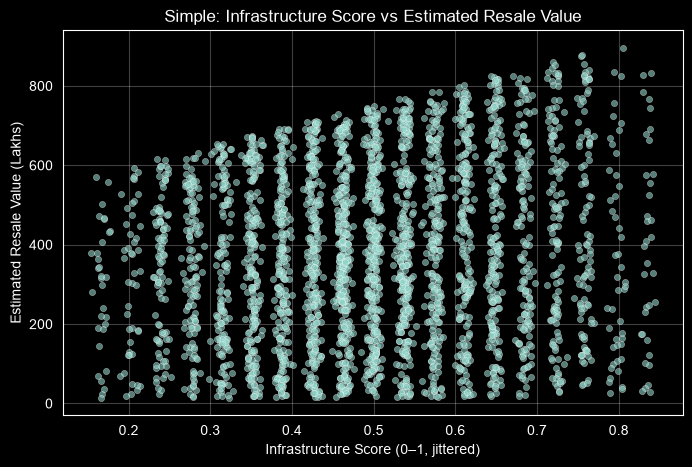

In [14]:
# Robust creation of Infra_Score and Estimated_Resale_Value + simple plot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# Make sure df_clean exists
assert "df_clean" in globals() or "df_clean" in locals(), "df_clean not found — run preprocessing first."

# Work on df_clean (no chained assignment)
df = df_clean.copy()

infra_cols = ["Nearby_Schools", "Nearby_Hospitals", "Public_Transport_Accessibility"]
price_col = "Price_in_Lakhs"

# 1) Ensure infra columns exist; if missing create and fill with 0
for c in infra_cols:
    if c not in df.columns:
        df[c] = 0.0

# 2) Convert to numeric and fill missing
for c in infra_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    # If entire column is NaN (or no variation) fill with 0 (neutral)
    if df[c].isna().all():
        df[c] = 0.0
    else:
        # fill NaNs with column median (safe)
        df[c] = df[c].fillna(df[c].median())

# 3) If a column is constant (min == max), avoid MinMaxScaler failing by setting scaled to 0.5
scaled = np.zeros((len(df), len(infra_cols)))
for i, c in enumerate(infra_cols):
    col_min = df[c].min()
    col_max = df[c].max()
    if col_min == col_max:
        # constant column -> map to 0.5
        scaled[:, i] = 0.5
    else:
        # normal min-max scaling
        scaled[:, i] = (df[c] - col_min) / (col_max - col_min)

# 4) Compute Infra_Score as mean of scaled infra features (0..1)
df["Infra_Score"] = np.nanmean(scaled, axis=1)

# 5) Ensure Price_in_Lakhs numeric and filled
if price_col not in df.columns:
    raise KeyError(f"Price column '{price_col}' not found. Columns: {list(df.columns)}")
df[price_col] = pd.to_numeric(df[price_col], errors="coerce")
df[price_col] = df[price_col].fillna(df[price_col].median())

# 6) Compute Estimated_Resale_Value (simple proxy)
df["Estimated_Resale_Value"] = df[price_col] * (1 + df["Infra_Score"])

# 7) Show quick summary so you can verify
print("Infra_Score stats:", df["Infra_Score"].min(), "to", df["Infra_Score"].max())
print("Number of NaNs in Infra_Score:", df["Infra_Score"].isna().sum())
print("Estimated_Resale_Value sample:")
display(df[[price_col, "Infra_Score", "Estimated_Resale_Value"]].sample(6, random_state=1))

# 8) Simple plot (sample for speed). Add jitter to make points visible if many overlap.
sample_n = min(3000, len(df))
plot_df = df.sample(sample_n, random_state=42).copy()
# jitter Infra_Score a bit for visibility
plot_df["Infra_Jitter"] = plot_df["Infra_Score"] + np.random.normal(scale=0.005, size=len(plot_df))

plt.figure(figsize=(8,5))
sns.scatterplot(data=plot_df, x="Infra_Jitter", y="Estimated_Resale_Value", alpha=0.6, s=20)
plt.xlabel("Infrastructure Score (0–1, jittered)")
plt.ylabel("Estimated Resale Value (Lakhs)")
plt.title("Simple: Infrastructure Score vs Estimated Resale Value")
plt.grid(alpha=0.25)
plt.show()

# 9) Assign back to df_clean so following cells can use these columns
df_clean["Infra_Score"] = df["Infra_Score"].values
df_clean["Estimated_Resale_Value"] = df["Estimated_Resale_Value"].values

Model Development

In [15]:
df_clean[["good_investment", "Estimated_Resale_Value"]].head()
df_clean["Estimated_Resale_Value"] = df_clean["Price_in_Lakhs"] * (1 + df_clean["Infra_Score"])
# CLASSIFICATION TARGET
y_class = df_clean["good_investment"]

# REGRESSION TARGET
y_reg = df_clean["Estimated_Resale_Value"]

A) Classification Model → Target: good_investment

(Models: Logistic Regression, Random Forest, XGBoost)

Split Features & Targets

In [16]:
from sklearn.model_selection import train_test_split
# Build feature matrix X
drop_cols = ["ID", "good_investment", "Estimated_Resale_Value"]

X = df_clean.drop(columns=[c for c in drop_cols if c in df_clean.columns])

# Convert categorical → one hot
X = pd.get_dummies(X, drop_first=True)

# Fix: Fill all remaining NaNs
X = X.fillna(0)

# Targets
y_class = df_clean["good_investment"].astype(int)
y_reg    = df_clean["Estimated_Resale_Value"].astype(float)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=42
)

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

print("Classification Shapes:", X_train_c.shape, X_test_c.shape)
print("Regression Shapes:", X_train_r.shape, X_test_r.shape)

Classification Shapes: (200000, 911) (50000, 911)
Regression Shapes: (200000, 911) (50000, 911)


i. **Logistic Regression**

Logistic Regression is a foundational linear classification model used to estimate the probability of a binary event occurring

(e.g., probability of a property being a "good investment")

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, classification_report

# -----------------------------
# 1) Target & Feature Setup
# -----------------------------

df = df_clean.copy()

# Regression target should not be used in classification features
leakage_cols = ["Estimated_Resale_Value", "price_per_sqft", "loc_median", "Price_in_Lakhs"]
leakage_cols = [c for c in leakage_cols if c in df.columns]

df = df.drop(columns=leakage_cols)

# Target column
y = df["good_investment"].astype(int)

# Feature matrix
X = df.drop(columns=["good_investment"])

# -----------------------------
# 2) Split Data
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# -----------------------------
# 3) Column Types
# -----------------------------
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object"]).columns

# -----------------------------
# 4) Preprocessing Pipeline
# -----------------------------
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# -----------------------------
# 5) Logistic Regression Pipeline
# -----------------------------
model = Pipeline([
    ("preprocess", preprocessor),
    ("logreg", LogisticRegression(max_iter=5000, solver="lbfgs"))
])

# -----------------------------
# 6) Train Model
# -----------------------------
model.fit(X_train, y_train)

# -----------------------------
# 7) Predictions
# -----------------------------
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

# -----------------------------
# 8) Evaluation Metrics
# -----------------------------
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
roc = roc_auc_score(y_test, y_prob)

print("\n===== LOGISTIC REGRESSION METRICS =====")
print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("ROC AUC  :", roc)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

C:\Users\aqibo\AppData\Local\Temp\ipykernel_23288\3555475392.py:37: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include=["object"]).columns



===== LOGISTIC REGRESSION METRICS =====
Accuracy : 0.98512
Precision: 0.9736729034022108
Recall   : 0.9971996639596752
ROC AUC  : 0.9990754399866862

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.97      0.98     25003
           1       0.97      1.00      0.99     24997

    accuracy                           0.99     50000
   macro avg       0.99      0.99      0.99     50000
weighted avg       0.99      0.99      0.99     50000



ii. **Random Forest Classifier**

This model typically offers significantly higher predictive performance compared to the Logistic Regression baseline you previously ran.

In [18]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(n_estimators=200, random_state=42)
rf_clf.fit(X_train_c, y_train_c)

y_pred_rf = rf_clf.predict(X_test_c)
y_prob_rf = rf_clf.predict_proba(X_test_c)[:,1]

print("📌 Random Forest Classifier Results")
print("Accuracy:", accuracy_score(y_test_c, y_pred_rf))
print("Precision:", precision_score(y_test_c, y_pred_rf))
print("Recall:", recall_score(y_test_c, y_pred_rf))
print("ROC AUC:", roc_auc_score(y_test_c, y_prob_rf))

📌 Random Forest Classifier Results
Accuracy: 0.99786
Precision: 0.9967217047135489
Recall: 0.9989982368969386
ROC AUC: 0.9999881655633416


iii. **XGBoost Classifier**

XGBoost Classifier, which is typically the most powerful and is an advanced implementation of the Gradient Boosting Machine (GBM) algorithm ,highest-performing model for structured, tabular data .

In [19]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42
)

xgb_clf.fit(X_train_c, y_train_c)

y_pred_xgb = xgb_clf.predict(X_test_c)
y_prob_xgb = xgb_clf.predict_proba(X_test_c)[:,1]

print("📌 XGBoost Classifier Results")
print("Accuracy:", accuracy_score(y_test_c, y_pred_xgb))
print("Precision:", precision_score(y_test_c, y_pred_xgb))
print("Recall:", recall_score(y_test_c, y_pred_xgb))
print("ROC AUC:", roc_auc_score(y_test_c, y_prob_xgb))

📌 XGBoost Classifier Results
Accuracy: 0.99892
Precision: 0.9987981732232994
Recall: 0.999038307421061
ROC AUC: 0.9999973775918768


**B) REGRESSION MODELS**

(Models : Linear Regression , Random Forest Regressor , XGBoost Regressor )

i. Linear Regression

Linear Regression model to predict the continuous target variable, Estimated_Resale_Value. It serves as the standard, interpretable baseline model forregression task, just as Logistic Regression did for classification task.

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lin_reg = LinearRegression()
lin_reg.fit(X_train_r, y_train_r)

y_pred_lin = lin_reg.predict(X_test_r)

print("📌 Linear Regression Results")
print("MAE:", mean_absolute_error(y_test_r, y_pred_lin))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, y_pred_lin)))
print("R²:", r2_score(y_test_r, y_pred_lin))

📌 Linear Regression Results
MAE: 15.087247813997385
RMSE: 21.278245694321285
R²: 0.990306995602338


ii. **Random Forest Regressor**

Random Forest Regressor is a highly optimized, much faster version of Gradient Boosting Machine (similar to XGBoost's approach) designed to handle large datasets efficiently.

In [21]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

hgb = HistGradientBoostingRegressor(
    max_depth=8,
    learning_rate=0.1,
    random_state=42
)

hgb.fit(X_train_r, y_train_r)
y_pred_hgb = hgb.predict(X_test_r)

print("📌 Random Forest Regressor ")
print("MAE:", mean_absolute_error(y_test_r, y_pred_hgb))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, y_pred_hgb)))
print("R²:", r2_score(y_test_r, y_pred_hgb))

📌 Random Forest Regressor 
MAE: 1.2402710582023484
RMSE: 1.5761312189552337
R²: 0.9999468171613869


iii. **XGBoost Regressor**

XGBoost Regressor, which is the gold standard for high-performance prediction tasks on tabular data, aiming to maximize the accuracy of predicting the continuous target, Estimated_Resale_Value.

The XGBoost Regressor shares the same theoretical foundation as the XGBoost Classifier: it is an optimized Gradient Boosting ensemble method.

In [22]:
from xgboost import XGBRegressor

xgb_reg = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.7,
    colsample_bytree=0.7,
    random_state=42
)

xgb_reg.fit(X_train_r, y_train_r)
y_pred_xgb_r = xgb_reg.predict(X_test_r)

print("📌 XGBoost Regressor Results")
print("MAE:", mean_absolute_error(y_test_r, y_pred_xgb_r))
print("RMSE:", np.sqrt(mean_squared_error(y_test_r, y_pred_xgb_r)))
print("R²:", r2_score(y_test_r, y_pred_xgb_r))

📌 XGBoost Regressor Results
MAE: 1.6245399943369832
RMSE: 2.1179753080373915
R²: 0.9999039652176194


**MLflow Integration**

In [37]:
"""
MLflow tracking + model registry for the Real_Estate notebook.

Run this AFTER the notebook cells that create:
    X_train_c, X_test_c, y_train_c, y_test_c   (classification split)
    X_train_r, X_test_r, y_train_r, y_test_r   (regression split)

Install once:  pip install mlflow xgboost scikit-learn
"""
import numpy as np
import mlflow
import mlflow.sklearn
import mlflow.xgboost
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, roc_auc_score,
    mean_absolute_error, mean_squared_error, r2_score,
)
from xgboost import XGBClassifier, XGBRegressor

# ------------------------------------------------------------------
# 0) Tracking server (localhost)
#    Start the server FIRST in a separate terminal:
#        mlflow server --host 127.0.0.1 --port 5000
#    (The server stores runs/registry in ./mlruns + a local DB by default,
#     so the Model Registry works without extra flags.)
# ------------------------------------------------------------------
mlflow.set_tracking_uri("http://127.0.0.1:5000")
client = MlflowClient()

CLF_EXPERIMENT = "India_Housing_Good_Investment_Classification"
REG_EXPERIMENT = "India_Housing_Resale_Value_Regression"


# ------------------------------------------------------------------
# 1) Helpers
# ------------------------------------------------------------------
def run_classifier(name, model, flavor, registered_name):
    """Train, evaluate and log one classifier. Returns (roc_auc, run_id)."""
    with mlflow.start_run(run_name=name) as run:
        model.fit(X_train_c, y_train_c)
        pred = model.predict(X_test_c)
        prob = model.predict_proba(X_test_c)[:, 1]

        metrics = {
            "accuracy": accuracy_score(y_test_c, pred),
            "precision": precision_score(y_test_c, pred),
            "recall": recall_score(y_test_c, pred),
            "roc_auc": roc_auc_score(y_test_c, prob),
        }

        mlflow.set_tags({"task": "classification", "target": "good_investment",
                         "algorithm": name})
        mlflow.log_params({"n_features": X_train_c.shape[1],
                           "n_train": X_train_c.shape[0],
                           "n_test": X_test_c.shape[0]})
        mlflow.log_params({f"model__{k}": v for k, v in model.get_params().items()
                           if isinstance(v, (int, float, str, bool, type(None)))})
        mlflow.log_metrics(metrics)

        sig = infer_signature(
            X_test_c.head(100),
            model.predict(X_test_c.head(100))
        )


        if flavor == "xgboost":
            model_info = mlflow.xgboost.log_model(
                model,
                name="model",
                signature=sig,
                input_example=X_test_c.head(5),
                registered_model_name=registered_name
            )
        else:
            model_info = mlflow.sklearn.log_model(
                model,
                name="model",
                signature=sig,
                input_example=X_test_c.head(5),
                registered_model_name=registered_name,
                serialization_format="pickle"
            )


    print(
    f"{name:<24} acc={metrics['accuracy']:.4f} "
    f"auc={metrics['roc_auc']:.5f}"
)

    return metrics["roc_auc"], run.info.run_id


def run_regressor(name, model, flavor, registered_name):
    """Train, evaluate and log one regressor. Returns (r2, run_id)."""
    with mlflow.start_run(run_name=name) as run:
        model.fit(X_train_r, y_train_r)
        pred = model.predict(X_test_r)

        metrics = {
            "mae": mean_absolute_error(y_test_r, pred),
            "rmse": float(np.sqrt(mean_squared_error(y_test_r, pred))),
            "r2": r2_score(y_test_r, pred),
        }

        mlflow.set_tags({"task": "regression", "target": "Estimated_Resale_Value",
                         "algorithm": name})
        mlflow.log_params({"n_features": X_train_r.shape[1],
                           "n_train": X_train_r.shape[0],
                           "n_test": X_test_r.shape[0]})
        mlflow.log_params({f"model__{k}": v for k, v in model.get_params().items()
                           if isinstance(v, (int, float, str, bool, type(None)))})
        mlflow.log_metrics(metrics)

        sig = infer_signature(
            X_test_r.head(100),
            model.predict(X_test_r.head(100))
        )


        if flavor == "xgboost":
            model_info = mlflow.xgboost.log_model(
                model,
                name="model",
                signature=sig,
                input_example=X_test_r.head(5),
                registered_model_name=registered_name
            )
        else:
            model_info = mlflow.sklearn.log_model(
                model,
                name="model",
                signature=sig,
                input_example=X_test_r.head(5),
                registered_model_name=registered_name,
                serialization_format="pickle"
            )


    print(
    f"{name:<24} "
    f"MAE={metrics['mae']:.3f} "
    f"RMSE={metrics['rmse']:.3f} "
    f"R2={metrics['r2']:.5f}"
)

    return metrics["r2"], run.info.run_id



def promote_best(registered_name, run_id, alias="champion"):
    versions = client.search_model_versions(
        f"name='{registered_name}'"
    )

    for mv in versions:
        if mv.run_id == run_id:
            client.set_registered_model_alias(
                registered_name,
                alias,
                mv.version
            )
            print(
                f"  -> {registered_name} v{mv.version} "
                f"aliased as '{alias}'"
            )
            return

    raise ValueError(
        f"No version of '{registered_name}' found "
        f"for run ID '{run_id}'. Check the model logging "
        "and tracking server configuration."
    )


# ------------------------------------------------------------------
# 2) Classification experiment  (target: good_investment)
# ------------------------------------------------------------------
mlflow.set_experiment(CLF_EXPERIMENT)

classifiers = [
    ("Logistic_Regression",
     Pipeline([("scale", StandardScaler()),
               ("logreg", LogisticRegression(max_iter=5000))]),
     "sklearn", "good_investment_logreg"),
    ("Random_Forest_Classifier",
     RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
     "sklearn", "good_investment_rf"),
    ("XGBoost_Classifier",
     XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6,
                   subsample=0.7, colsample_bytree=0.7, random_state=42),
     "xgboost", "good_investment_xgb"),
]

clf_results = {}
for name, mdl, flavor, reg_name in classifiers:
    score, rid = run_classifier(name, mdl, flavor, reg_name)
    clf_results[reg_name] = (score, rid)

best_clf = max(clf_results, key=lambda k: clf_results[k][0])
print("Best classifier:", best_clf)
promote_best(best_clf, clf_results[best_clf][1])

# ------------------------------------------------------------------
# 3) Regression experiment  (target: Estimated_Resale_Value)
# ------------------------------------------------------------------
mlflow.set_experiment(REG_EXPERIMENT)

regressors = [
    ("Linear_Regression", LinearRegression(), "sklearn", "resale_value_linreg"),
    # your notebook labels this "Random Forest Regressor", but the model used is
    # HistGradientBoostingRegressor, so it is logged under its real name.
    ("HistGradientBoosting_Regressor",
     HistGradientBoostingRegressor(max_depth=8, learning_rate=0.1, random_state=42),
     "sklearn", "resale_value_hgb"),
    ("XGBoost_Regressor",
     XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                  subsample=0.7, colsample_bytree=0.7, random_state=42),
     "xgboost", "resale_value_xgb"),
]

reg_results = {}
for name, mdl, flavor, reg_name in regressors:
    score, rid = run_regressor(name, mdl, flavor, reg_name)
    reg_results[reg_name] = (score, rid)

best_reg = max(reg_results, key=lambda k: reg_results[k][0])
print("Best regressor:", best_reg)
promote_best(best_reg, reg_results[best_reg][1])

# ------------------------------------------------------------------
# 4) Load the registered champions back (for inference / deployment)
# ------------------------------------------------------------------
champ_clf = mlflow.pyfunc.load_model(f"models:/{best_clf}@champion")
champ_reg = mlflow.pyfunc.load_model(f"models:/{best_reg}@champion")

print("Sample classification preds:", champ_clf.predict(X_test_c.head(5)))
print("Sample regression preds:   ", champ_reg.predict(X_test_r.head(5)))

# View everything at http://127.0.0.1:5000


C:\Users\aqibo\PycharmProjects\PythonProject\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/13 18:54:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exe

🏃 View run Logistic_Regression at: http://127.0.0.1:5000/#/experiments/1/runs/459f7d262f624729bb5685d5ed49da22
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Logistic_Regression      acc=0.9964 auc=0.99996


C:\Users\aqibo\PycharmProjects\PythonProject\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/13 18:55:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exe

🏃 View run Random_Forest_Classifier at: http://127.0.0.1:5000/#/experiments/1/runs/f2d264bbb8384b5697d0f1941b2589de
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Random_Forest_Classifier acc=0.9979 auc=0.99999


C:\Users\aqibo\PycharmProjects\PythonProject\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
Registered model 'good_investment_xgb' already exists. Creating a new version of this model...
2026/10/13 18:56:00 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish c

...

🏃 View run Linear_Regression at: http://127.0.0.1:5000/#/experiments/2/runs/d886972b432f4b97aacb04735087f512
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
Linear_Regression        MAE=15.087 RMSE=21.278 R2=0.99031


C:\Users\aqibo\PycharmProjects\PythonProject\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/10/13 18:57:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can exe

🏃 View run HistGradientBoosting_Regressor at: http://127.0.0.1:5000/#/experiments/2/runs/7f346a84846f483cbef5e46af967e86c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
HistGradientBoosting_Regressor MAE=1.240 RMSE=1.576 R2=0.99995


C:\Users\aqibo\PycharmProjects\PythonProject\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
Registered model 'resale_value_xgb' already exists. Creating a new version of this model...
2026/10/13 18:57:39 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish crea

🏃 View run XGBoost_Regressor at: http://127.0.0.1:5000/#/experiments/2/runs/a4dff6e9acfc41249766055ce880ca5c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
XGBoost_Regressor        MAE=1.625 RMSE=2.118 R2=0.99990
Best regressor: resale_value_hgb
  -> resale_value_hgb v2 aliased as 'champion'
Sample classification preds: [0 1 1 0 1]
Sample regression preds:    [393.89126819 128.807997   359.59783523 559.49611135 200.02306546]


In [38]:
# A: inspect columns & dtypes
from pathlib import Path
import pandas as pd

CSV_PATH = Path(r"C:\Users\aqibo\PycharmProjects\PythonProject\india_housing_prices.csv")
print("CSV path:", CSV_PATH)
df = pd.read_csv(CSV_PATH, nrows=5)   # quick read
print("Columns:", list(df.columns))
display(df.head())
display(df.dtypes)

CSV path: C:\Users\aqibo\PycharmProjects\PythonProject\india_housing_prices.csv
Columns: ['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility', 'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type', 'Availability_Status']


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


ID                                  int64
State                                 str
City                                  str
Locality                              str
Property_Type                         str
BHK                                 int64
Size_in_SqFt                        int64
Price_in_Lakhs                    float64
Price_per_SqFt                    float64
Year_Built                          int64
Furnished_Status                      str
Floor_No                            int64
Total_Floors                        int64
Age_of_Property                     int64
Nearby_Schools                      int64
Nearby_Hospitals                    int64
Public_Transport_Accessibility        str
Parking_Space                         str
Security                              str
Amenities                             str
Facing                                str
Owner_Type                            str
Availability_Status                   str
dtype: object

In [39]:
# B: clean Price_in_Lakhs
import pandas as pd
df_full = pd.read_csv(CSV_PATH)
TARGET_COL = "Price_in_Lakhs"

# Clean non-numeric chars then convert
df_full[TARGET_COL] = df_full[TARGET_COL].astype(str).str.replace(r'[^0-9.\-]', '', regex=True)
df_full[TARGET_COL] = pd.to_numeric(df_full[TARGET_COL], errors='coerce')

print(f"Target column: {TARGET_COL}")
print("dtype:", df_full[TARGET_COL].dtype)
print("NA count:", int(df_full[TARGET_COL].isna().sum()))
display(df_full[TARGET_COL].describe())

Target column: Price_in_Lakhs
dtype: float64
NA count: 0


count    250000.000000
mean        254.586854
std         141.349921
min          10.000000
25%         132.550000
50%         253.870000
75%         376.880000
max         500.000000
Name: Price_in_Lakhs, dtype: float64

In [41]:
# list runs
# list runs
from mlflow.tracking import MlflowClient

client = MlflowClient()

# Use your exact experiment name variable here
experiment_name = "India_Housing_Good_Investment_Classification"  # or REG_EXPERIMENT
exp = client.get_experiment_by_name(experiment_name)

if exp:
  runs = client.search_runs(
      [exp.experiment_id], order_by=["attributes.start_time DESC"], max_results=20
  )
  for r in runs:
    print(r.info.run_id, r.info.run_name, r.data.metrics)
else:
  print(f"Experiment '{experiment_name}' not found!")

3a73212c587b42c6bdccefecf9ac653e XGBoost_Classifier {'accuracy': 0.99892, 'precision': 0.9987981732232994, 'recall': 0.999038307421061, 'roc_auc': 0.9999973775918768}
f2d264bbb8384b5697d0f1941b2589de Random_Forest_Classifier {'accuracy': 0.99786, 'precision': 0.9967217047135489, 'recall': 0.9989982368969386, 'roc_auc': 0.9999881655633416}
459f7d262f624729bb5685d5ed49da22 Logistic_Regression {'accuracy': 0.9964, 'precision': 0.995718287314926, 'recall': 0.9970748517390607, 'roc_auc': 0.999955534262263}
412bcb24a96844d9885462fb8ca213ed Random_Forest_Classifier {'accuracy': 0.99786, 'precision': 0.9967217047135489, 'recall': 0.9989982368969386, 'roc_auc': 0.9999881655633416}
734353b459904df6be1252443b6740e9 Logistic_Regression {'accuracy': 0.9964, 'precision': 0.995718287314926, 'recall': 0.9970748517390607, 'roc_auc': 0.999955534262263}
c4a73e48f21048aab52ec00efddca263 XGBoost_Classifier {'accuracy': 0.99892, 'precision': 0.9987981732232994, 'recall': 0.999038307421061, 'roc_auc': 0.9999